In [1]:
from sklearn.datasets import fetch_openml
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Import datast
mnist = fetch_openml('mnist_784', version=1)
X, y = torch.tensor(mnist["data"].to_numpy()), torch.tensor(mnist["target"].to_numpy().astype(int))


In [2]:
# train test split
X_train_raw, X_test_raw, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

# minmax scaling - scaled based on test set to avoid leakage
X_min = X_train_raw.min() # note this would return just one scaler
X_max = X_train_raw.max()

X_train = (X_train_raw - X_min)/(X_max - X_min) # , would broadcast across both dims to apply to every element
X_test = (X_test_raw - X_min)/(X_max - X_min)


In [3]:
X_train.shape, y_train.shape

(torch.Size([60000, 784]), torch.Size([60000]))

(array([38847859.,   571880.,   514157.,   438029.,   446644.,   503214.,
          469607.,   518723.,   611860.,  4118027.]),
 array([0.        , 0.1       , 0.2       , 0.30000001, 0.40000001,
        0.5       , 0.60000002, 0.69999999, 0.80000001, 0.90000004,
        1.        ]),
 <BarContainer object of 10 artists>)

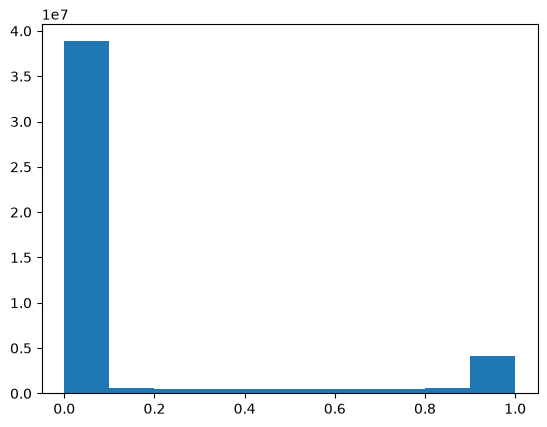

In [4]:
# confirm we between 0 and 1
plt.hist(X_train.flatten())

In [5]:
# lets start with 784 inputs -> 256 -> 128 -> 10 outputs, relu activations, softmax final
torch.manual_seed(42)

# sizes
num_inputs = X_train.shape[1]
num_hidden_1 = 256
num_hidden_2 = 128
num_outputs = 10

# first layer
W1 = torch.randn(num_inputs, num_hidden_1).float() * (2/num_inputs)**0.5 # kaiming init, with reLu gain = sqrt(2), fan in = num_inputs
b1 = torch.zeros(num_hidden_1)

# second
W2 = torch.randn(num_hidden_1, num_hidden_2).float() * (2/num_hidden_1)**0.5
b2 = torch.zeros(num_hidden_2)

# third
W3 = torch.randn(num_hidden_2, num_outputs).float() * (2/num_hidden_2)**0.5
b3 = torch.zeros(num_outputs)

# no batchnorm for now
params = [W1, b1, W2, b2, W3, b3]
for p in params:
    p.requires_grad = True


In [6]:
# try a forward pass no loop

# first layer
preact1 = X_train @ W1 + b1
act1 = torch.relu(preact1)

# second
preact2 = act1 @ W2 + b2
act2 = torch.relu(preact2)

logits = act2 @ W3 + b3
loss = F.cross_entropy(logits, y_train)
loss


# note we have 10 digits - even probabilities across the digits would give us a cross entropy loss of -ln(1/10) so thats what we need to beat

tensor(2.4201, grad_fn=<NllLossBackward0>)

In [7]:
# now loop it see what happens

iterations = 10000
batch_size = 32

for i in range(iterations):

    # batching
    ix = torch.randint(0, X_train_raw.shape[0], (batch_size, ))
    Xb, yb = X_train[ix], y_train[ix]

    # forward pass
    # first layer
    preact1 = X_train @ W1 + b1
    act1 = torch.relu(preact1)

    # second
    preact2 = act1 @ W2 + b2
    act2 = torch.relu(preact2)

    logits = act2 @ W3 + b3
    loss = F.cross_entropy(logits, y_train)

    # backward pass
    # propagate
    for p in params:
        p.grad = None
    loss.backward()

    lr = 0.05
    for p in params:
        p.data += -lr * p.grad


    if i % 10 == 0:
        print(f"iteration {i}: loss {loss.item()}")

iteration 0: loss 2.4200661182403564
iteration 10: loss 1.8171969652175903
iteration 20: loss 1.402561902999878
iteration 30: loss 1.0910308361053467
iteration 40: loss 0.885013222694397
iteration 50: loss 0.7528829574584961
iteration 60: loss 0.6648108959197998
iteration 70: loss 0.60269695520401
iteration 80: loss 0.5566505193710327
iteration 90: loss 0.5211107134819031
iteration 100: loss 0.49281832575798035
iteration 110: loss 0.4696967303752899
iteration 120: loss 0.45043763518333435
iteration 130: loss 0.43411141633987427
iteration 140: loss 0.42004403471946716
iteration 150: loss 0.40777555108070374
iteration 160: loss 0.3969603180885315
iteration 170: loss 0.387333482503891
iteration 180: loss 0.37869319319725037
iteration 190: loss 0.3708694279193878
iteration 200: loss 0.3637407422065735
iteration 210: loss 0.3572027087211609
iteration 220: loss 0.3511667549610138
iteration 230: loss 0.34557533264160156
iteration 240: loss 0.34036698937416077
iteration 250: loss 0.33549743890

KeyboardInterrupt: 

(array([[0.        , 0.15606036, 0.9103521 , ..., 0.13005034, 0.05202014,
         0.        ],
        [0.        , 0.10404024, 0.72828168, ..., 0.39015102, 0.02601007,
         0.        ],
        [0.02601007, 0.05202012, 0.9103521 , ..., 0.39015102, 0.02601007,
         0.        ],
        ...,
        [0.        , 0.07803018, 0.9103521 , ..., 0.44217115, 0.        ,
         0.        ],
        [0.        , 0.10404024, 0.98838228, ..., 0.33813088, 0.        ,
         0.02601005],
        [0.        , 0.02601006, 0.72828168, ..., 0.39015102, 0.        ,
         0.02601005]], shape=(256, 10)),
 array([-0.23144215, -0.18240306, -0.13336395, -0.08432484, -0.03528574,
         0.01375335,  0.06279248,  0.11183158,  0.16087067,  0.20990977,
         0.25894889]),
 <a list of 256 BarContainer objects>)

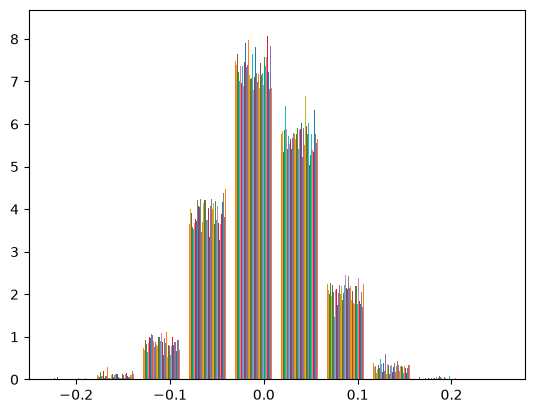

In [8]:
plt.hist(W1.data, density=True)

In [9]:
# inference on test set

preact1 = X_test @ W1 + b1
act1 = torch.relu(preact1)

preact2 = act1 @ W2 + b2
act2 = torch.relu(preact2)

logits = act2 @ W3 + b3
loss = F.cross_entropy(logits, y_test)
loss


tensor(0.1401, grad_fn=<NllLossBackward0>)

In [10]:
# get accuracy
y_pred = torch.argmax(logits, dim=1)
correct = (y_pred == y_test).float()
accuracy = correct.mean().item()
accuracy

0.9595000147819519